# VoltVision - Exploratory Data Analysis (EDA)

## 1. Import Libraries

In this notebook, we will explore EV charging patterns,
energy consumption, charging costs, and station-level trends.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("../data/processed/ev_charging_cleaned.csv")

df.head()

,User ID,Vehicle Model,Battery Capacity (kWh),Charging Station ID,Charging Station Location,Charging Start Time,Charging End Time,Energy Consumed (kWh),Charging Duration (hours),Charging Rate (kW),...,Vehicle Age (years),Charger Type,User Type,Calculated Duration (hours),Duration Difference,Expected Energy (kWh),Energy Difference,Absolute Energy Difference,Cost per kWh,Energy to Battery Capacity (%)
0,User_1,BMW i3,108.463007,Station_391,Houston,2024-01-01 00:00:00,2024-01-01 00:39:00,60.712346,0.591363,36.389181,...,2.0,DC Fast Charger,Commuter,0.650000,-0.058637,23.652967,37.059378,37.059378,0.215569,55.975163
1,User_2,Hyundai Kona,100.000000,Station_428,San Francisco,2024-01-01 01:00:00,2024-01-01 03:01:00,12.339275,3.133652,30.677735,...,3.0,Level 1,Casual Driver,2.016667,1.116985,61.866765,-49.527490,49.527490,1.712292,12.339275
2,User_3,Chevy Bolt,75.000000,Station_181,San Francisco,2024-01-01 02:00:00,2024-01-01 04:48:00,19.128876,2.452653,27.513593,...,2.0,Level 2,Commuter,2.800000,-0.347347,77.038059,-57.909183,57.909183,1.864577,25.505168
3,User_4,Hyundai Kona,50.000000,Station_327,Houston,2024-01-01 03:00:00,2024-01-01 06:42:00,79.457824,1.266431,32.882870,...,1.0,Level 1,Long-Distance Traveler,3.700000,-2.433569,121.666618,-42.208794,42.208794,0.164065,158.915648
4,User_5,Hyundai Kona,50.000000,Station_108,Los Angeles,2024-01-01 04:00:00,2024-01-01 05:46:00,19.629104,2.019765,10.215712,...,1.0,Level 1,Long-Distance Traveler,1.766667,0.253098,18.047758,1.581346,1.581346,0.517674,39.258208


## 3. Dataset Overview

In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (1320, 27)

Column Names:
['User ID', 'Vehicle Model', 'Battery Capacity (kWh)', 'Charging Station ID', 'Charging Station Location', 'Charging Start Time', 'Charging End Time', 'Energy Consumed (kWh)', 'Charging Duration (hours)', 'Charging Rate (kW)', 'Charging Cost (USD)', 'Time of Day', 'Day of Week', 'State of Charge (Start %)', 'State of Charge (End %)', 'Distance Driven (since last charge) (km)', 'Temperature (°C)', 'Vehicle Age (years)', 'Charger Type', 'User Type', 'Calculated Duration (hours)', 'Duration Difference', 'Expected Energy (kWh)', 'Energy Difference', 'Absolute Energy Difference', 'Cost per kWh', 'Energy to Battery Capacity (%)']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1320 entries, 0 to 1319
Data columns (total 27 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   User ID                                   1320 non-

## 4. Convert DateTime Columns

In [4]:
datetime_columns = [
    "Charging Start Time",
    "Charging End Time"
]

for column in datetime_columns:
    df[column] = pd.to_datetime(df[column], errors="coerce")

df[datetime_columns].dtypes

Charging Start Time    datetime64[ns]
Charging End Time      datetime64[ns]
dtype: object

## 5. Numerical Features Statistical Analysis

In [5]:
numerical_summary = df.describe().T

display(numerical_summary)

,count,mean,min,25%,50%,75%,max,std
Battery Capacity (kWh),1320.0,74.534692,1.532807,62.0,75.0,85.0,193.003074,20.626914
Charging Start Time,1320,2024-01-28 11:30:00,2024-01-01 00:00:00,2024-01-14 17:45:00,2024-01-28 11:30:00,2024-02-11 05:15:00,2024-02-24 23:00:00,NaN
Charging End Time,1320,2024-01-28 13:43:30.863636480,2024-01-01 00:39:00,2024-01-14 19:34:30,2024-01-28 14:07:00,2024-02-11 07:39:00,2024-02-24 23:56:00,NaN
Energy Consumed (kWh),1320.0,42.64532,0.045772,24.868084,42.691405,60.545496,152.238758,21.843794
Charging Duration (hours),1320.0,2.269377,0.095314,1.397623,2.258136,3.112806,7.635145,1.061037
Charging Rate (kW),1320.0,25.945043,1.472549,14.431294,25.603799,36.955838,97.342255,13.656504
Charging Cost (USD),1320.0,22.551352,0.234317,13.368141,22.07636,31.646044,69.407743,10.751494
State of Charge (Start %),1311.0,48.654553,2.325959,27.731774,47.992183,68.736181,98.332795,23.431086
State of Charge (End %),1297.0,74.254404,7.604224,61.931297,75.07975,87.470102,99.986604,15.594023
Distance Driven (since last charge) (km),1320.0,153.529942,0.862361,81.931571,152.259867,221.96233,398.364775,83.826126


## 6. Categorical Features Distribution

In [6]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for column in categorical_columns:
    print(f"\n{column}")
    display(df[column].value_counts())


User ID


User ID
User_1       1
User_887     1
User_885     1
User_884     1
User_883     1
            ..
User_440     1
User_439     1
User_438     1
User_437     1
User_1320    1
Name: count, Length: 1320, dtype: int64


Vehicle Model


Vehicle Model
Tesla Model 3    280
Hyundai Kona     266
Nissan Leaf      260
BMW i3           258
Chevy Bolt       256
Name: count, dtype: int64


Charging Station ID


Charging Station ID
Station_108    9
Station_17     7
Station_97     7
Station_74     7
Station_10     7
              ..
Station_331    1
Station_440    1
Station_70     1
Station_375    1
Station_374    1
Name: count, Length: 462, dtype: int64

... (6 outputs left out)


Charger Type


Charger Type
Level 1            459
Level 2            431
DC Fast Charger    430
Name: count, dtype: int64


User Type


User Type
Commuter                  476
Long-Distance Traveler    437
Casual Driver             407
Name: count, dtype: int64

## 7. Vehicle Model Distribution

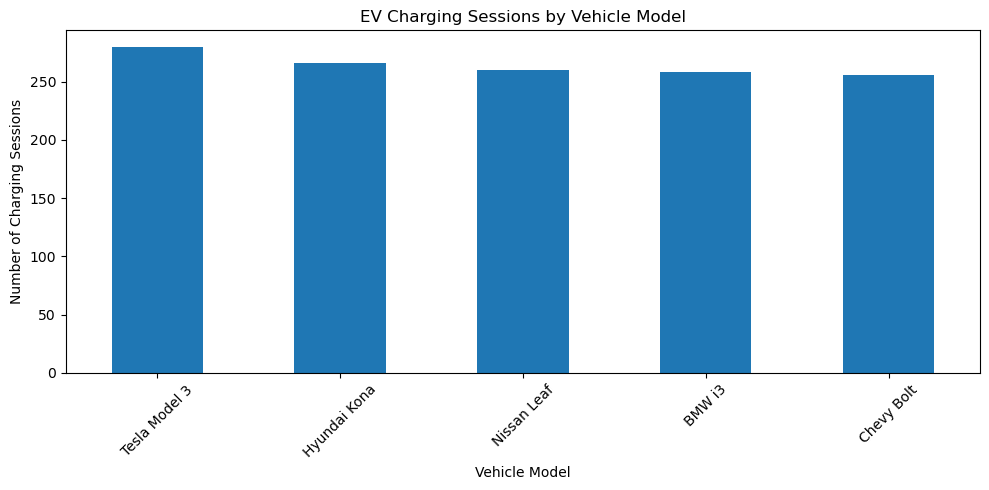

In [7]:
vehicle_counts = df["Vehicle Model"].value_counts()

vehicle_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("EV Charging Sessions by Vehicle Model")
plt.xlabel("Vehicle Model")
plt.ylabel("Number of Charging Sessions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Charging Station Location Analysis

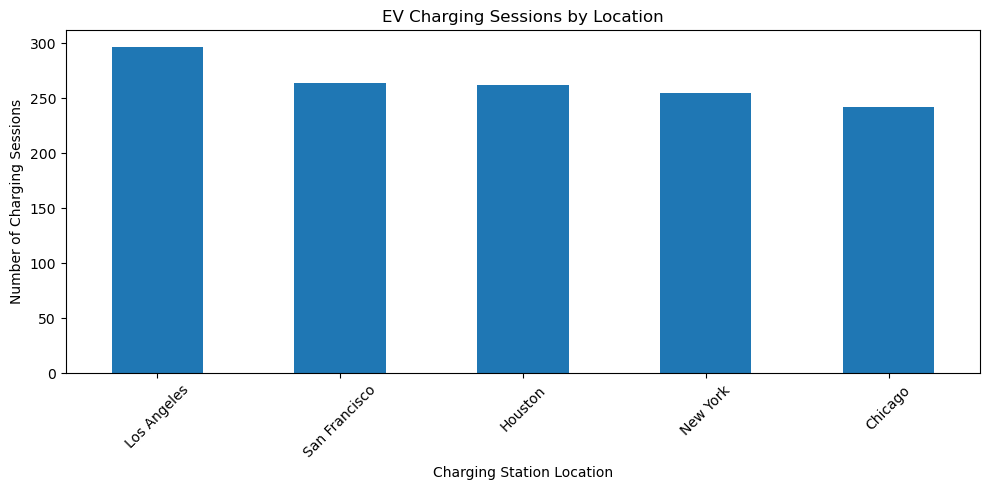

In [8]:
location_counts = df["Charging Station Location"].value_counts()

location_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("EV Charging Sessions by Location")
plt.xlabel("Charging Station Location")
plt.ylabel("Number of Charging Sessions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. Charger Type Analysis

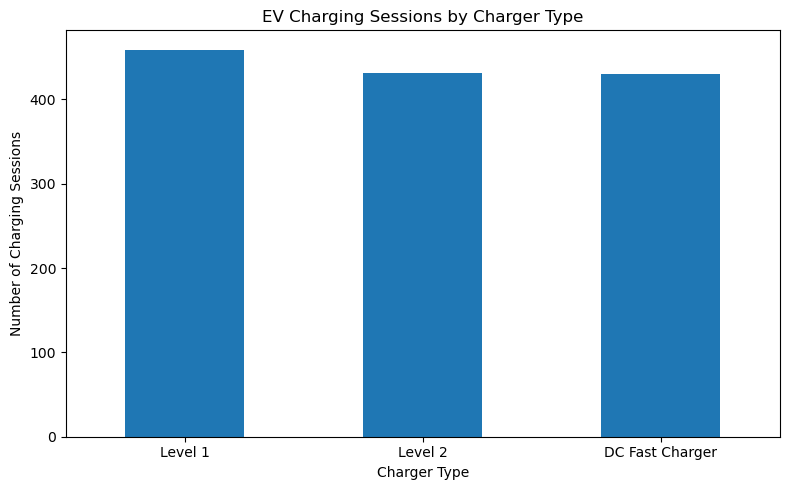

In [9]:
charger_counts = df["Charger Type"].value_counts()

charger_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("EV Charging Sessions by Charger Type")
plt.xlabel("Charger Type")
plt.ylabel("Number of Charging Sessions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. User Type Analysis

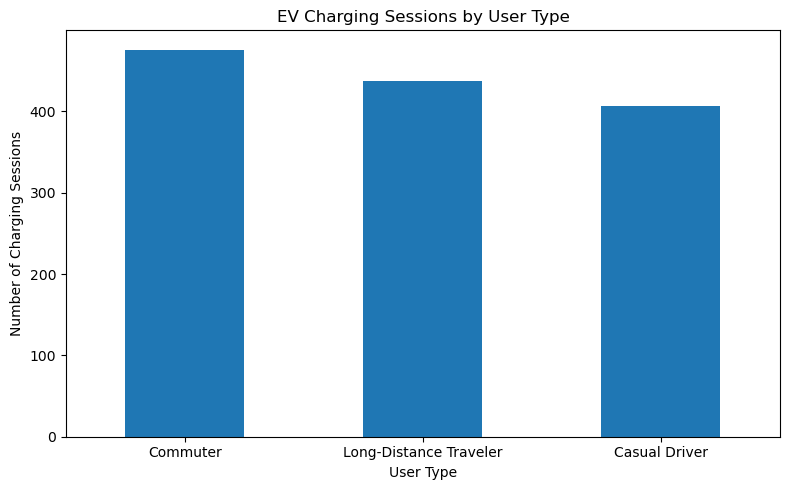

In [10]:
user_counts = df["User Type"].value_counts()

user_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("EV Charging Sessions by User Type")
plt.xlabel("User Type")
plt.ylabel("Number of Charging Sessions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Time of Day Charging Analysis

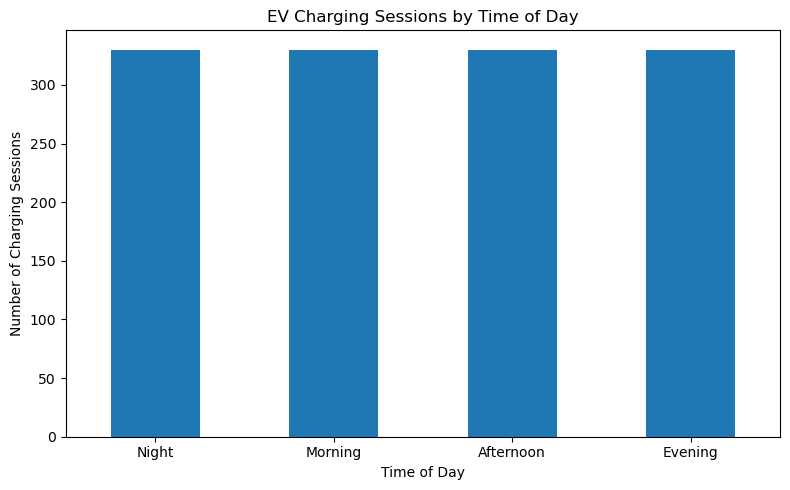

In [11]:
time_counts = df["Time of Day"].value_counts()

time_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("EV Charging Sessions by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Number of Charging Sessions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 12. Day of Week Charging Analysis

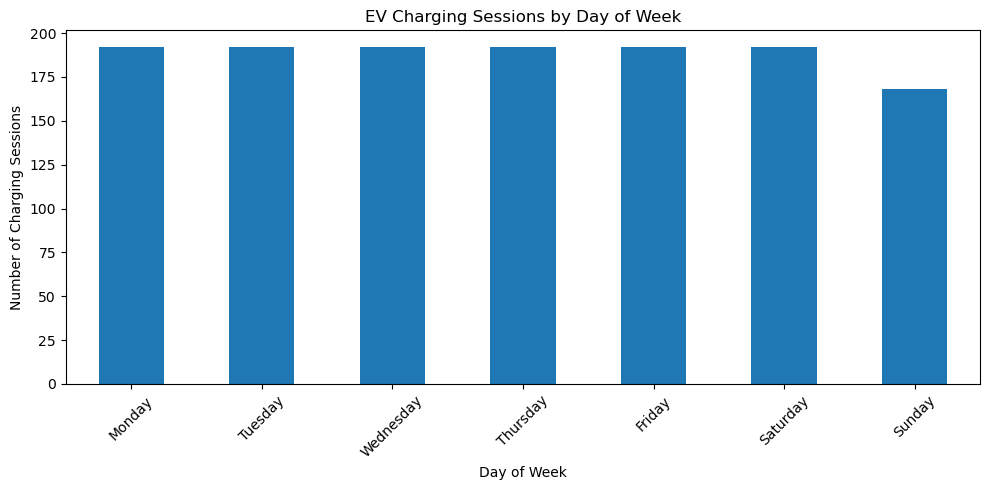

In [12]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_counts = df["Day of Week"].value_counts().reindex(day_order)

day_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("EV Charging Sessions by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Charging Sessions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 13.Part 1 : Energy Consumption Analysis

In [13]:
energy_by_vehicle = df.groupby("Vehicle Model")["Energy Consumed (kWh)"].mean()

energy_by_vehicle = energy_by_vehicle.sort_values(ascending=False)

display(energy_by_vehicle)

Vehicle Model
Tesla Model 3    44.420454
Hyundai Kona     42.825293
Nissan Leaf      42.514366
BMW i3           42.457526
Chevy Bolt       40.839024
Name: Energy Consumed (kWh), dtype: float64

## Part 2 :  Average Energy Consumption by Vehicle Model

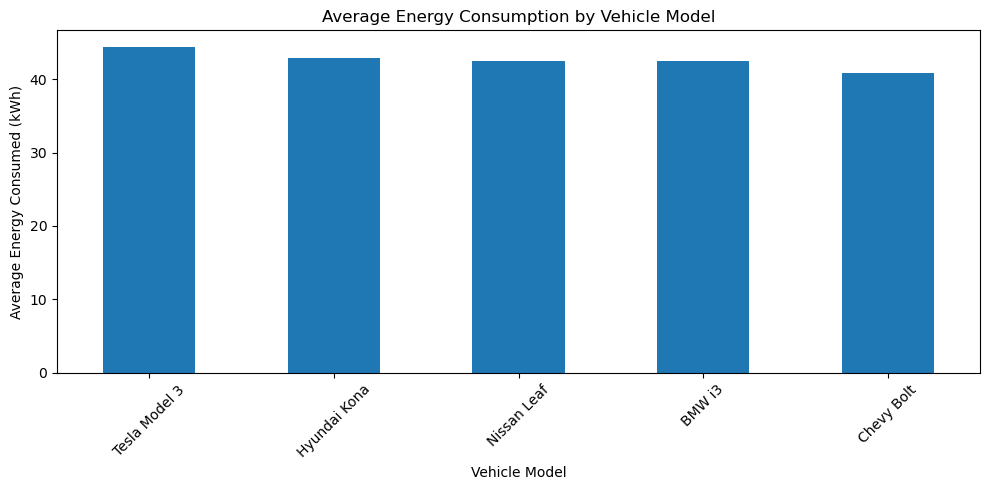

In [14]:
energy_by_vehicle.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Energy Consumption by Vehicle Model")
plt.xlabel("Vehicle Model")
plt.ylabel("Average Energy Consumed (kWh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 14. Part 1 : Charging Cost Analysis

In [15]:
cost_by_vehicle = df.groupby("Vehicle Model")["Charging Cost (USD)"].mean()

cost_by_vehicle = cost_by_vehicle.sort_values(ascending=False)

display(cost_by_vehicle)

Vehicle Model
Nissan Leaf      23.654672
Hyundai Kona     23.436081
Tesla Model 3    22.579682
Chevy Bolt       22.264301
BMW i3           20.781396
Name: Charging Cost (USD), dtype: float64

## Part 2 : Average Charging Cost by Vehicle Model

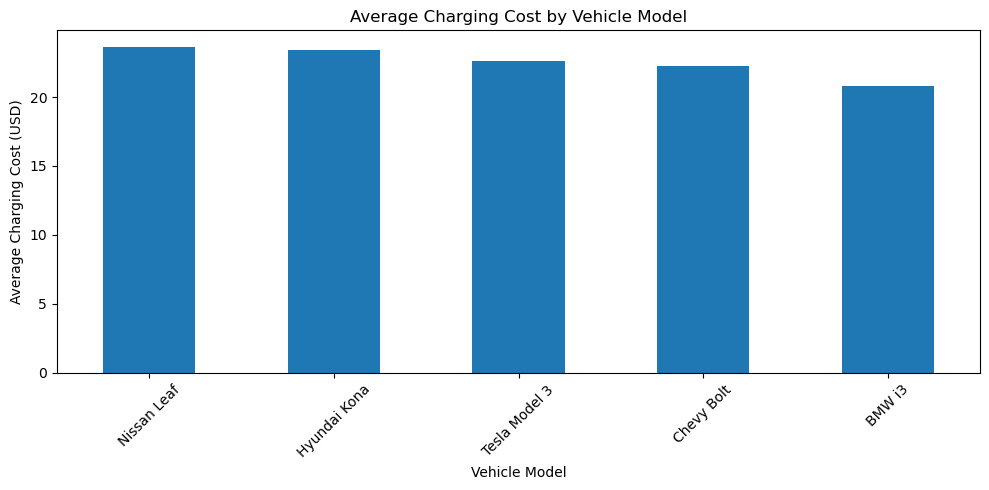

In [16]:
cost_by_vehicle.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Charging Cost by Vehicle Model")
plt.xlabel("Vehicle Model")
plt.ylabel("Average Charging Cost (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 15. Part 1 :Charging Duration Analysis

In [17]:
duration_by_vehicle = df.groupby("Vehicle Model")["Calculated Duration (hours)"].mean()

duration_by_vehicle = duration_by_vehicle.sort_values(ascending=False)

display(duration_by_vehicle)

Vehicle Model
BMW i3           2.261951
Chevy Bolt       2.260742
Hyundai Kona     2.241353
Tesla Model 3    2.203214
Nissan Leaf      2.161090
Name: Calculated Duration (hours), dtype: float64

## Part 2 : Average Charging Duration by Vehicle Model

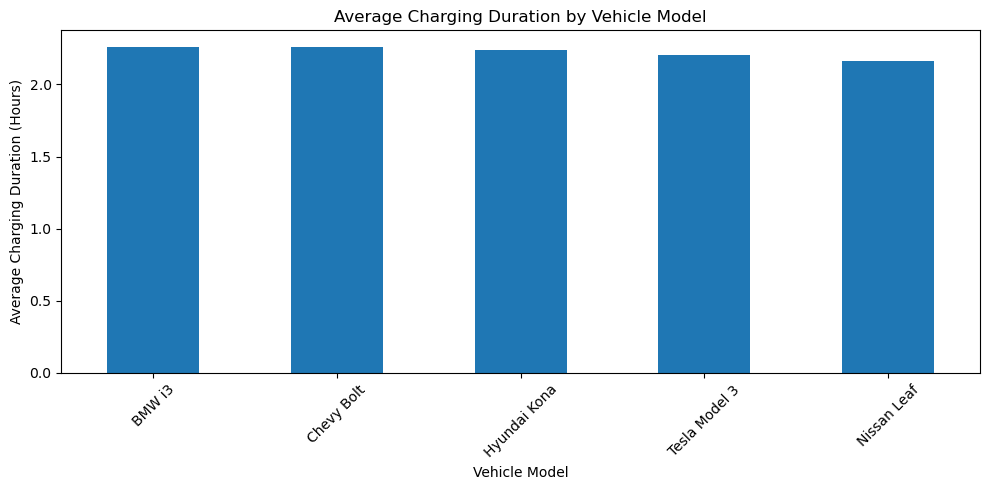

In [18]:
duration_by_vehicle.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Charging Duration by Vehicle Model")
plt.xlabel("Vehicle Model")
plt.ylabel("Average Charging Duration (Hours)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 16. Part 1 : Charging Trends Over Time

In [19]:
daily_sessions = (
    df.groupby(df["Charging Start Time"].dt.date)
    .size()
)

display(daily_sessions.head(10))

Charging Start Time
2024-01-01    24
2024-01-02    24
2024-01-03    24
2024-01-04    24
2024-01-05    24
2024-01-06    24
2024-01-07    24
2024-01-08    24
2024-01-09    24
2024-01-10    24
dtype: int64

## Part 2 : Daily EV Charging Sessions Trend

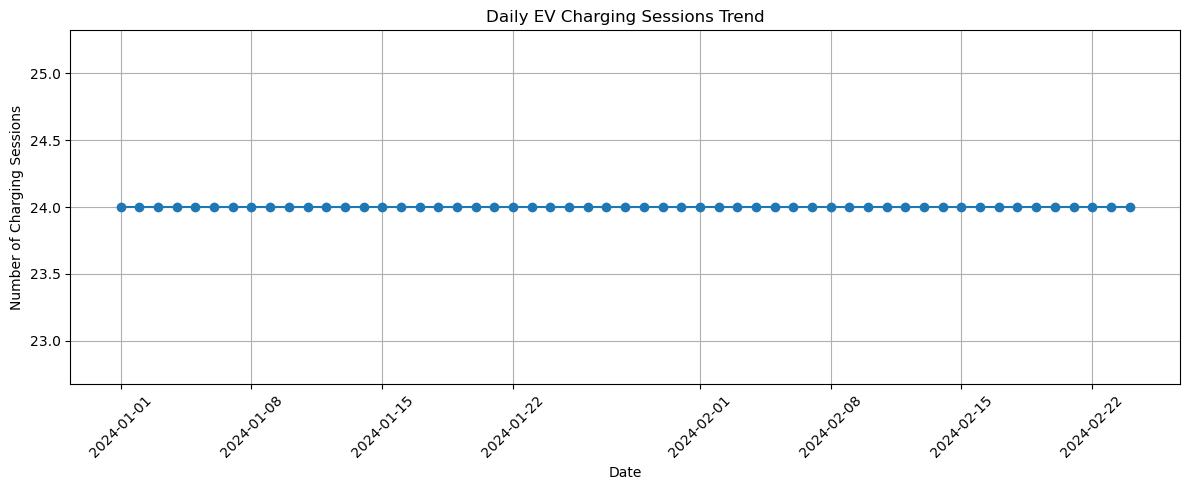

In [20]:
plt.figure(figsize=(12, 5))

daily_sessions.plot(kind="line", marker="o")

plt.title("Daily EV Charging Sessions Trend")
plt.xlabel("Date")
plt.ylabel("Number of Charging Sessions")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## 17. Part 1 : Correlation Analysis

In [21]:
correlation_columns = [
    "Battery Capacity (kWh)",
    "Energy Consumed (kWh)",
    "Calculated Duration (hours)",
    "Charging Rate (kW)",
    "Charging Cost (USD)",
    "State of Charge (Start %)",
    "State of Charge (End %)",
    "Distance Driven (since last charge) (km)",
    "Temperature (°C)",
    "Vehicle Age (years)"
]

correlation_data = df[correlation_columns]

correlation_matrix = correlation_data.corr()

display(correlation_matrix)

,Battery Capacity (kWh),Energy Consumed (kWh),Calculated Duration (hours),Charging Rate (kW),Charging Cost (USD),State of Charge (Start %),State of Charge (End %),Distance Driven (since last charge) (km),Temperature (°C),Vehicle Age (years)
Battery Capacity (kWh),1.000000,0.000328,0.038394,0.015691,-0.000492,-0.068342,-0.006239,-0.040130,-0.036411,0.037673
Energy Consumed (kWh),0.000328,1.000000,-0.034647,-0.040002,-0.007603,-0.018937,0.026215,-0.026378,-0.017993,0.016744
Calculated Duration (hours),0.038394,-0.034647,1.000000,0.008314,0.004326,-0.016779,-0.037612,0.022483,-0.037830,0.023689
Charging Rate (kW),0.015691,-0.040002,0.008314,1.000000,-0.000924,-0.016195,-0.007881,0.030493,0.012445,-0.049038
Charging Cost (USD),-0.000492,-0.007603,0.004326,-0.000924,1.000000,-0.013805,-0.049496,-0.008318,0.059864,-0.006487
State of Charge (Start %),-0.068342,-0.018937,-0.016779,-0.016195,-0.013805,1.000000,-0.019885,-0.029327,0.040019,0.032640
State of Charge (End %),-0.006239,0.026215,-0.037612,-0.007881,-0.049496,-0.019885,1.000000,0.014426,0.007996,0.011034
Distance Driven (since last charge) (km),-0.040130,-0.026378,0.022483,0.030493,-0.008318,-0.029327,0.014426,1.000000,-0.022961,-0.030835
Temperature (°C),-0.036411,-0.017993,-0.037830,0.012445,0.059864,0.040019,0.007996,-0.022961,1.000000,0.026410
Vehicle Age (years),0.037673,0.016744,0.023689,-0.049038,-0.006487,0.032640,0.011034,-0.030835,0.026410,1.000000


## Part 2 : Correlation Heatmap

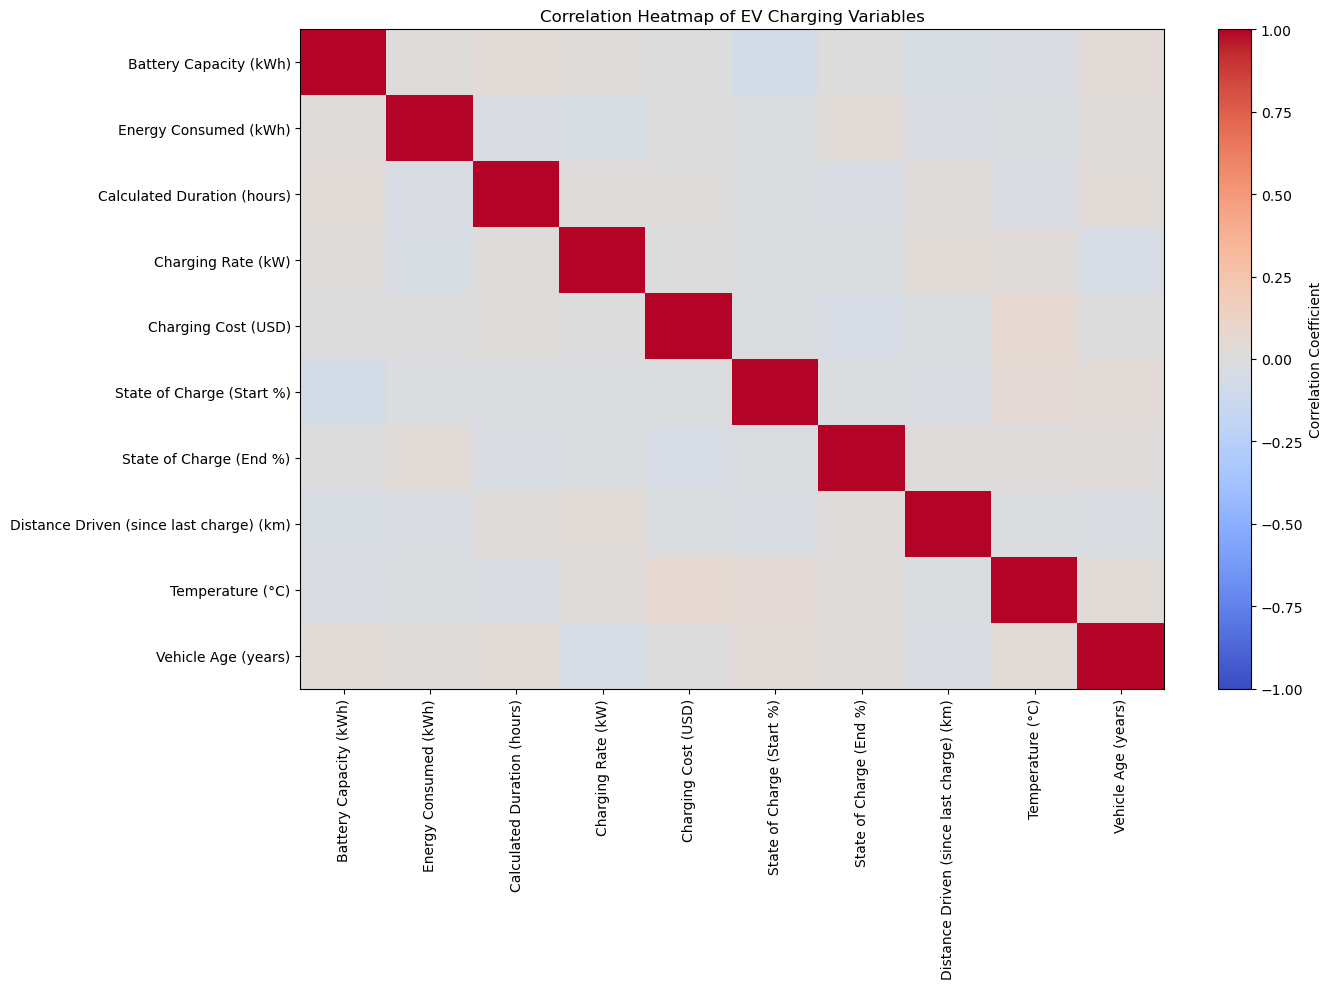

In [22]:
plt.figure(figsize=(14, 10))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    interpolation="nearest",
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)

plt.title("Correlation Heatmap of EV Charging Variables")

plt.tight_layout()
plt.show()

## 18. Part 1 : Business Insights & Findings

In [23]:
print("TOTAL CHARGING SESSIONS:", len(df))

print("\nAVERAGE ENERGY CONSUMPTION:")
print(round(df["Energy Consumed (kWh)"].mean(), 2), "kWh")

print("\nAVERAGE CHARGING COST:")
print("$", round(df["Charging Cost (USD)"].mean(), 2))

print("\nAVERAGE CHARGING DURATION:")
print(round(df["Calculated Duration (hours)"].mean(), 2), "hours")

print("\nMOST USED VEHICLE MODEL:")
print(df["Vehicle Model"].value_counts().idxmax())

print("\nMOST USED CHARGER TYPE:")
print(df["Charger Type"].value_counts().idxmax())

print("\nMOST ACTIVE LOCATION:")
print(df["Charging Station Location"].value_counts().idxmax())

print("\nMOST ACTIVE USER TYPE:")
print(df["User Type"].value_counts().idxmax())

TOTAL CHARGING SESSIONS: 1320

AVERAGE ENERGY CONSUMPTION:
42.65 kWh

AVERAGE CHARGING COST:
$ 22.55

AVERAGE CHARGING DURATION:
2.23 hours

MOST USED VEHICLE MODEL:
Tesla Model 3

MOST USED CHARGER TYPE:
Level 1

MOST ACTIVE LOCATION:
Los Angeles

MOST ACTIVE USER TYPE:
Commuter


### Final Exploratory Data Analysis Summary

The VoltVision dataset contains 1,320 EV charging sessions and 27 columns.

Key findings from the exploratory analysis:

- Tesla Model 3 recorded the highest number of charging sessions.
- Los Angeles had the highest number of recorded sessions.
- Level 1 was the most frequently used charger type.
- Commuters represented the largest user category.
- Average energy consumption was 42.65 kWh.
- Average charging cost was $22.55.
- Average calculated charging duration was 2.23 hours.
- Charging sessions were equally distributed across all four time-of-day categories.
- Daily charging sessions remained constant at 24 per day.
- Most numerical variables showed very weak linear correlations.

### Data Quality Considerations

The analysis identified several unusual patterns and inconsistencies.

The dataset shows signs of artificial balancing, including identical daily session counts and equal time-of-day distributions.

Therefore, the findings should be interpreted as patterns within the available dataset rather than verified real-world EV charging behaviour.

No statistical outliers were automatically removed during the analysis.